# RegExplain: E2 — ISM and DeepLIFT

Explain **E1 Tier 0 Model 1 (seed 565)** using ISM and DeepLIFT. Load its trained weights and keep them fixed throughout E2.


**Outputs:** motif AUPRC against the planted-motif mask (computed as average precision, AP), ISM/DeepLIFT agreement, deletion curves and AUC with a random control, reference sensitivity, and an attribution logo with planted motif positions. Each result or figure has its own code cell.

**Sample:** 200 randomly selected positive test sequences, including any misclassified by the CNN. All methods use the same sequences. The PDF specifies 200 test sequences but not their class composition; positives are used because every sequence then has planted positions for motif AP. Conclusions apply to this positive-only sample.

E2 here uses Tier 0 ground truth. Tier 1 has no planted-position mask; the second Tier 0 model is available for future tasks.


## 1. Imports and settings

Use the environment already installed for E1.


In [21]:
# Import the E1 environment packages and set reproducible execution.
from pathlib import Path
from importlib.metadata import version
import sys, random, warnings, json, zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import logomaker
from urllib.request import urlretrieve
from captum.attr import DeepLift
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score

torch.manual_seed(565)
torch.set_num_threads(2)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("e2_results")
out.mkdir(exist_ok=True)
print("Device:", device, "| PyTorch:", version("torch"), "| Captum:", version("captum"))


Device: cpu | PyTorch: 2.14.1 | Captum: 0.9.0


## 2. Load the trained model and test data

Recreate the E1 architecture, load its saved weights, and freeze them. No training is performed.


In [22]:
# Load E1 Model 1 and keep its trained weights fixed.
folder = Path("e1_results/tier0_seed565")
data = np.load(folder / "data.npz")
checkpoint = torch.load(folder / "model.pt", map_location=device, weights_only=True)
cnn = nn.Sequential(
    nn.Conv1d(4, 64, 15, padding=7), nn.ReLU(), nn.MaxPool1d(2),
    nn.Conv1d(64, 64, 7, padding=3), nn.ReLU(), nn.MaxPool1d(50),
    nn.Flatten(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1)
).to(device)
cnn.load_state_dict(checkpoint["state_dict"])
model = nn.Sequential(cnn, nn.Sigmoid()).eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)

def onehot(seqs):
    return torch.from_numpy(np.eye(4, dtype=np.float32)[seqs].transpose(0, 2, 1)).to(device)

def predict(seqs):
    with torch.no_grad():
        return torch.cat([model(onehot(seqs[i:i + 256])).cpu() for i in range(0, len(seqs), 256)]).numpy().ravel()

print("E1 Model 1 loaded; weights frozen.")


E1 Model 1 loaded; weights frozen.


## 3. Select the same 200 test sequences for every method

The sampling seed is fixed before looking at the results. Test indices are zero-based positions within E1's 1,500-sequence test split. Misclassified positives remain in the sample.

In [23]:
# Randomly sample positive test sequences; do not select by confidence or attribution quality.
indices = np.random.default_rng(565).choice(np.flatnonzero(data["y_test"] == 1), 200, replace=False)
X, mask = data["X_test"][indices], data["mask_test"][indices]
x, p = onehot(X), predict(X)
pd.DataFrame({"test_index": indices, "label": data["y_test"][indices], "probability": p,
              "motif_positions": mask.sum(axis=1)}).to_csv(out / "selected_sequences.csv", index=False)
print("Sequences:", X.shape, "| Motif-position fraction:", round(mask.mean(), 4))
print("Predicted positive at 0.5:", int((p >= 0.5).sum()), "of 200 (all 200 are retained).")


Sequences: (200, 101) | Motif-position fraction: 0.1438
Predicted positive at 0.5: 174 of 200 (all 200 are retained).


## 4. DeepLIFT references

Use the instructor's `dinuc_shuffle` helper to shuffle each input 10 times while preserving dinucleotide counts. Importing the helper does not rebuild Tier 1. Average the 10 one-hot sequences into **one reference per input**; this is not an average of 10 attribution runs. The comparison reference has 0.25 in every A/C/G/T channel.


In [24]:
# Use the official shuffle helper from the same fixed course commit as E1.
source = "https://raw.githubusercontent.com/yueliyl/RegExplain/4e496fea9460db51f2d0ab355681f53cab5a9cb4/"
urlretrieve(source + "build_tier1.py", "build_tier1.py")
sys.path.insert(0, str(Path.cwd()))
from build_tier1 import dinuc_shuffle

def shuffle(row, rng):
    text = dinuc_shuffle("".join("ACGT"[b] for b in row), rng)
    return np.array(["ACGT".index(b) for b in text], dtype=np.int8)

rng = random.Random(565)
shuffles = np.array([[shuffle(row, rng) for _ in range(10)] for row in X])
reference = onehot(shuffles.reshape(-1, 101)).reshape(200, 10, 4, 101).mean(dim=1)
uniform = torch.full_like(x, 0.25)
print("Mean shuffled references:", tuple(reference.shape), "| Shuffles per input: 10")


Mean shuffled references: (200, 4, 101) | Shuffles per input: 10


## 5. In-silico mutagenesis (ISM)

At each position, replace the original base by each of the **other three bases**. Every mutant differs at exactly one position. Run all 303 mutants per sequence in batches.

The signed score for position j is the mean of `P(original) - P(mutant)` over its three alternatives. We retain all three mutation effects as well as their mean. The PDF does not prescribe how to collapse the three changes, so this mean is an explicit analysis choice. Motif AP and deletion use the absolute value of this position score; Spearman agreement uses signed scores.

In [25]:
# Mutate each position to its three alternatives and compare binding probabilities.
def ism(seqs):
    mutants = np.repeat(seqs, 303, axis=0)
    positions = np.tile(np.repeat(np.arange(101), 3), len(seqs))
    rows = np.arange(len(mutants))
    mutants[rows, positions] = (mutants[rows, positions] + np.tile([1, 2, 3], 101 * len(seqs))) % 4
    return predict(seqs)[:, None, None] - predict(mutants).reshape(len(seqs), 101, 3)

mutation_effects = ism(X)
ism_score = mutation_effects.mean(axis=2)
print("ISM scores:", ism_score.shape)


ISM scores: (200, 101)


## 6. DeepLIFT Rescale

Compute contributions to binding probability relative to each reference. The four channel contributions at each position are summed; they are not multiplied by the one-hot input a second time.

The explanation model inserts an identity copy before each max-pooling layer to separate adjacent Captum hooks. Copies preserve the trained prediction function and weights. The printed completeness residual is the difference between total attribution and the input-minus-reference prediction difference.


In [26]:
# Separate Captum hook boundaries without changing the prediction function.
class CopyTensor(nn.Module):
    def forward(self, x):
        return x.clone()

layers = []
for layer in cnn:
    if isinstance(layer, nn.MaxPool1d):
        layers.append(CopyTensor())
    layers.append(layer)
explain_model = nn.Sequential(*layers, nn.Sigmoid()).eval()

def deeplift(baseline):
    values, deltas = [], []
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Setting forward, backward hooks.*", category=UserWarning)
        for i in range(0, 200, 32):
            a, d = DeepLift(explain_model).attribute(x[i:i + 32].detach().requires_grad_(),
                baselines=baseline[i:i + 32], return_convergence_delta=True)
            values.append(a.detach().cpu().numpy())
            deltas.append(d.detach().cpu().numpy())
    values, deltas = np.concatenate(values), np.concatenate(deltas)
    return values, deltas


### DeepLIFT: mean of 10 shuffled sequences

The four channel contributions at each position are summed, including contributions from changes away from the reference. They are not multiplied by the observed one-hot base a second time.

In [27]:
# Attribute to the mean shuffled reference, then sum all four channels per position.
dl_channels, dl_delta = deeplift(reference)
dl_score = dl_channels.sum(axis=1)
print("DeepLIFT scores:", dl_score.shape, "| Maximum absolute completeness residual:", abs(dl_delta).max())


DeepLIFT scores: (200, 101) | Maximum absolute completeness residual: 4.172325e-07


### DeepLIFT: uniform 0.25 reference

In [28]:
# Change only the reference; keep the model and selected sequences fixed.
uniform_channels, uniform_delta = deeplift(uniform)
uniform_score = uniform_channels.sum(axis=1)
print("Maximum absolute completeness residual:", abs(uniform_delta).max())


Maximum absolute completeness residual: 4.172325e-07


## 7. Ground-truth recovery: motif AP

Each of the 101 positions is a prediction item. The target is whether that position was planted as part of a motif. Scores are absolute signed position attributions. Compute AP separately for each of the 200 sequences and report the median and interquartile range (Q1 to Q3). Motif AP is the motif AUPRC that the PDF asks for, computed as average precision: the non-interpolated precision-recall summary, not trapezoidal PR area.

The random baseline assigns independent random scores to positions. A high motif AP means that planted positions tend to rank above background positions; it is not classification AUROC or accuracy.

In [29]:
# Compare absolute attribution scores with the known planted-position mask.
scores = {"ISM": ism_score, "DeepLIFT (shuffle)": dl_score, "DeepLIFT (uniform)": uniform_score}
random_scores = np.random.default_rng(566).random(X.shape)
ap = pd.DataFrame({name: [average_precision_score(truth, abs(score)) for truth, score in zip(mask, values)]
                   for name, values in {**scores, "Random": random_scores}.items()})

def summarize(frame):
    return pd.DataFrame({"n": frame.count(), "median": frame.median(),
                         "Q1": frame.quantile(0.25), "Q3": frame.quantile(0.75)})

print(summarize(ap).round(4).to_string())

                      n  median      Q1      Q3
ISM                 200  0.7339  0.5780  1.0000
DeepLIFT (shuffle)  200  0.7349  0.5732  0.9519
DeepLIFT (uniform)  200  0.7291  0.5733  1.0000
Random              200  0.1816  0.1215  0.2261


### Motif AP distribution

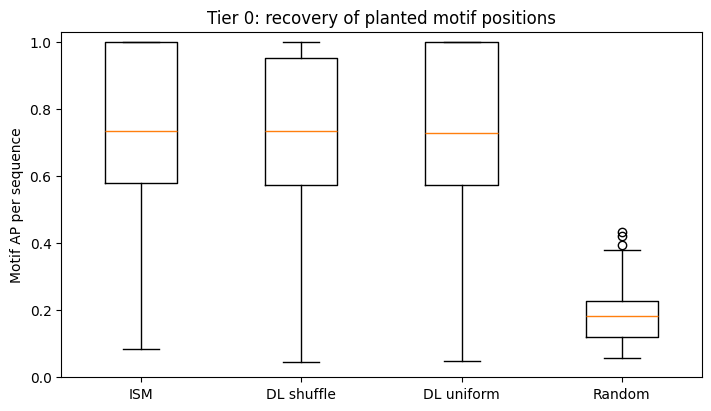

In [30]:
# Show the distribution across all 200 sequences, including outliers.
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.boxplot([ap[name] for name in ap], tick_labels=["ISM", "DL shuffle", "DL uniform", "Random"])
ax.set(title="Tier 0: recovery of planted motif positions", ylabel="Motif AP per sequence", ylim=(0, 1.03))
fig.savefig(out / "motif_AP.png", dpi=200)
plt.show()
plt.close(fig)

## 8. ISM / DeepLIFT agreement

Compute Spearman correlation between the **signed** 101-position score vectors within each sequence. A constant score vector has undefined correlation; retain it as NaN and report the count rather than pretending its correlation is zero.

In [31]:
# Correlate the position rankings separately for each selected test sequence.
def correlations(a, b):
    return np.array([spearmanr(u, v).statistic if np.ptp(u) > 0 and np.ptp(v) > 0 else np.nan
                     for u, v in zip(a, b)])

agreement = pd.DataFrame({"ISM vs DL shuffle": correlations(ism_score, dl_score),
                          "ISM vs DL uniform": correlations(ism_score, uniform_score)})
print(summarize(agreement).round(4).to_string())
print("Undefined correlations:", agreement.isna().sum().to_dict())

                     n  median      Q1      Q3
ISM vs DL shuffle  200  0.6478  0.5852  0.7161
ISM vs DL uniform  200  0.6473  0.5667  0.7227
Undefined correlations: {'ISM vs DL shuffle': 0, 'ISM vs DL uniform': 0}


### Agreement distribution

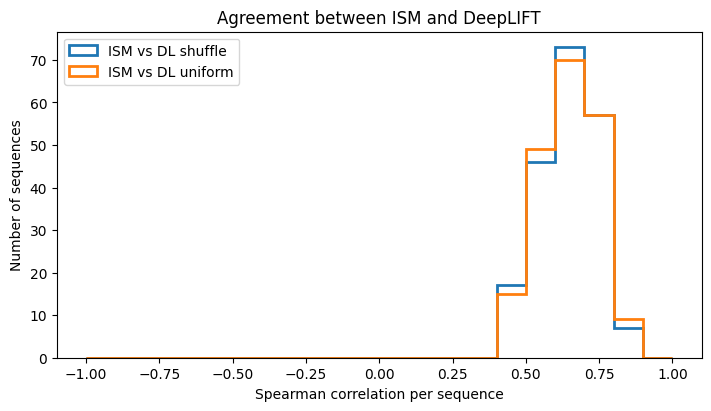

In [32]:
# Plot correlations for individual sequences rather than only a single mean.
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for name in agreement:
    ax.hist(agreement[name].dropna(), bins=np.linspace(-1, 1, 21), histtype="step", linewidth=2, label=name)
ax.set(title="Agreement between ISM and DeepLIFT", xlabel="Spearman correlation per sequence", ylabel="Number of sequences")
ax.legend()
fig.savefig(out / "agreement.png", dpi=200)
plt.show()
plt.close(fig)

## 9. Sensitivity to the DeepLIFT reference

Compare shuffled-reference and uniform-reference DeepLIFT on the same sequences. Report the distribution of their signed-score Spearman correlations and the change in motif AP (`uniform minus shuffle`). A high correlation alone does not guarantee identical attribution magnitudes or faithfulness.

In [33]:
# Measure reference sensitivity without assuming that either reference must win.
sensitivity = pd.DataFrame({"Shuffle vs uniform Spearman": correlations(dl_score, uniform_score),
                            "Motif AP change (uniform - shuffle)": ap["DeepLIFT (uniform)"] - ap["DeepLIFT (shuffle)"]})
print(summarize(sensitivity).round(4).to_string())
print("Undefined correlations:", int(sensitivity.iloc[:, 0].isna().sum()))

                                       n  median      Q1      Q3
Shuffle vs uniform Spearman          200  0.9047  0.8791  0.9243
Motif AP change (uniform - shuffle)  200  0.0000 -0.0085  0.0099
Undefined correlations: 0


### Reference-sensitivity distribution

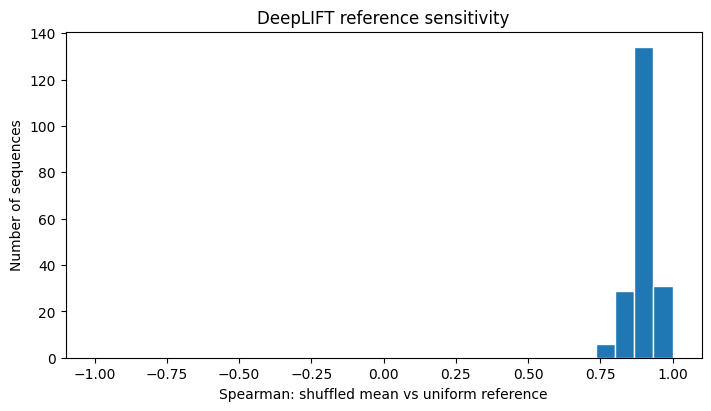

In [34]:
# Show how consistently the two references rank the sequence positions.
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.hist(sensitivity.iloc[:, 0].dropna(), bins=np.linspace(-1, 1, 31), edgecolor="white")
ax.set(title="DeepLIFT reference sensitivity", xlabel="Spearman: shuffled mean vs uniform reference", ylabel="Number of sequences")
fig.savefig(out / "reference_sensitivity.png", dpi=200)
plt.show()
plt.close(fig)

## 10. Deletion with a random-position control

Rank positions once by absolute attribution. At 0%, 10%, ..., 100%, replace the top positions with bases from a dinucleotide shuffle of that input. Keep sequence length 101; round to whole positions and use the actual selected fraction on the x-axis. A replacement base can match the original, so this fraction is not Hamming distance.

Average 10 independent replacement backgrounds per sequence. All methods share each background. The random control uses a fresh nested random ordering for each sequence and repeat; attribution ties use a fixed random tie-breaker. Rankings stay fixed during replacement.

Report both remaining probability and its drop. **Deletion AUC integrates remaining probability, so lower is better** (PDF Section 7.1). Curves can be non-monotonic because replacements can create motifs or remove negative contributions. Fully shuffled backgrounds preserve dinucleotide counts; partially replaced sequences need not.


In [35]:
# Compare all methods with matched background replacements and a random-position control.
steps = np.rint(np.linspace(0, 101, 11)).astype(int)
fractions = steps / 101
ties = np.random.default_rng(567).random(X.shape)
ranks = {name: np.argsort(np.lexsort((ties, -abs(values)), axis=1), axis=1) for name, values in scores.items()}
deletion = {name: np.empty((10, 200, len(steps))) for name in [*scores, "Random"]}
rng, order_rng = random.Random(566), np.random.default_rng(568)
for repeat in range(10):
    background = np.array([shuffle(row, rng) for row in X])
    ranks["Random"] = np.array([order_rng.permutation(101) for _ in X])
    for name, rank in ranks.items():
        for j, count in enumerate(steps):
            deletion[name][repeat, :, j] = predict(np.where(rank < count, background, X))
    print(f"Deletion repeat {repeat + 1}/10 complete.")

curves = {name: values.mean(axis=0) for name, values in deletion.items()}
deletion_auc = pd.DataFrame({name: np.trapezoid(values, x=fractions, axis=1) for name, values in curves.items()})


Deletion repeat 1/10 complete.
Deletion repeat 2/10 complete.
Deletion repeat 3/10 complete.
Deletion repeat 4/10 complete.
Deletion repeat 5/10 complete.
Deletion repeat 6/10 complete.
Deletion repeat 7/10 complete.
Deletion repeat 8/10 complete.
Deletion repeat 9/10 complete.
Deletion repeat 10/10 complete.


### Deletion AUC results

Each value below is the area for one sequence after averaging its 10 replacement repeats. Q1 and Q3 describe variation across sequences, not confidence intervals. Comparing with the random control is essential.

In [36]:
# Report per-sequence deletion AUC distributions and the mean-curve area.
deletion_summary = summarize(deletion_auc)
deletion_summary["mean_curve_AUC"] = deletion_auc.mean()
print(deletion_summary.round(4).to_string())

                      n  median      Q1      Q3  mean_curve_AUC
ISM                 200  0.3054  0.1981  0.4332          0.3314
DeepLIFT (shuffle)  200  0.2925  0.1865  0.4380          0.3280
DeepLIFT (uniform)  200  0.2994  0.2058  0.4488          0.3346
Random              200  0.4227  0.3188  0.5085          0.4109


### Deletion curve: remaining probability

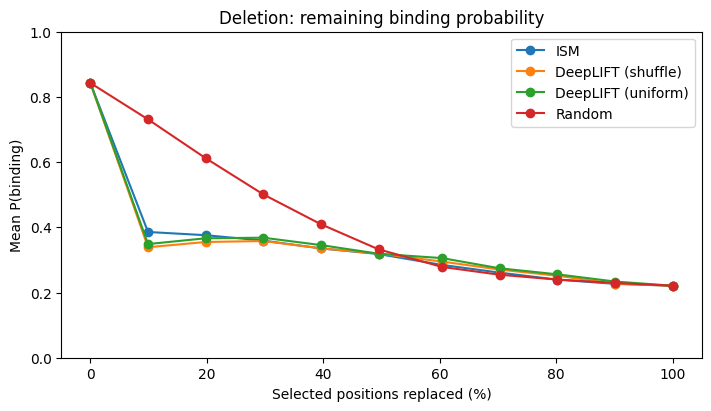

In [37]:
# Plot the curve whose area is reported as deletion AUC.
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for name, values in curves.items():
    ax.plot(100 * fractions, values.mean(axis=0), marker="o", label=name)
ax.set(title="Deletion: remaining binding probability", xlabel="Selected positions replaced (%)", ylabel="Mean P(binding)", ylim=(0, 1))
ax.legend()
fig.savefig(out / "deletion_probability.png", dpi=200)
plt.show()
plt.close(fig)

### Deletion curve: drop from the original prediction

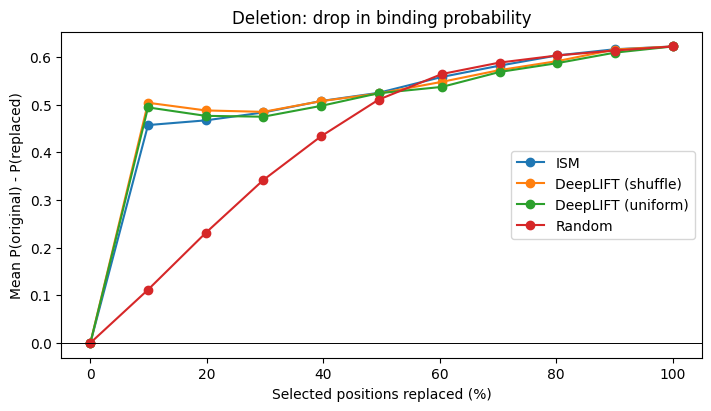

In [38]:
# Show the probability drop as requested in E2; do not use this area as deletion AUC.
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
for name, values in curves.items():
    ax.plot(100 * fractions, (p[:, None] - values).mean(axis=0), marker="o", label=name)
ax.axhline(0, color="black", linewidth=0.7)
ax.set(title="Deletion: drop in binding probability", xlabel="Selected positions replaced (%)", ylabel="Mean P(original) - P(replaced)")
ax.legend()
fig.savefig(out / "deletion_drop.png", dpi=200)
plt.show()
plt.close(fig)

## 11. A randomly selected bound sequence

Choose one of the 200 positive test sequences using a fixed seed, without inspecting its scores. Show its observed DNA letters scaled by the signed position attribution. For DeepLIFT, the displayed letter height is the **sum of all four channel contributions at that position**, not an additional multiplication of the raw channel scores. Gold bars mark the known planted positions. The three panels use their own y-scales, so compare position patterns rather than raw letter height across methods.

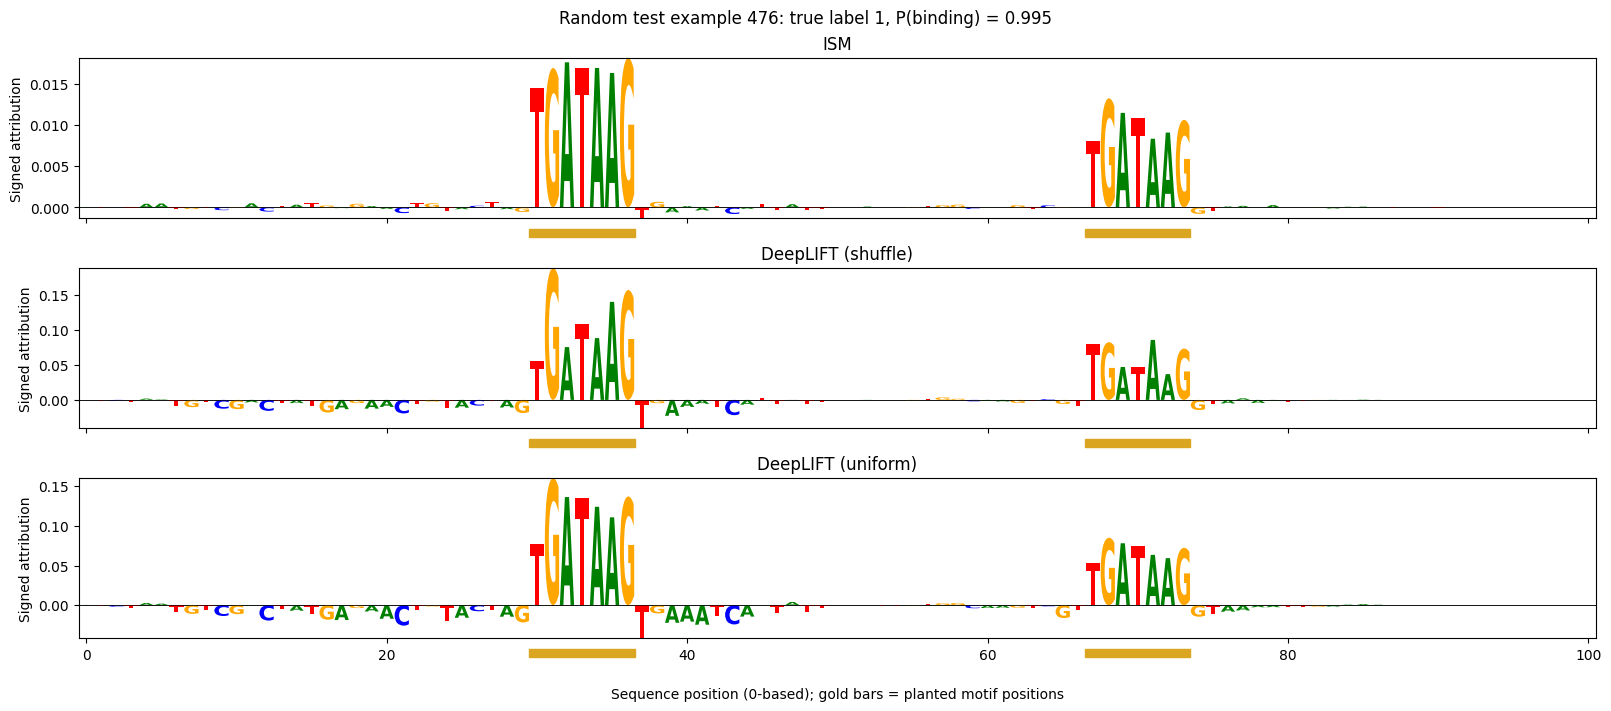

Example test index: 476 | Planted spans [start, end): [(30, 37), (67, 74)]


In [39]:
# Draw an independently selected example; mark every planted motif span underneath.
example = int(np.random.default_rng(569).integers(200))
edges = np.diff(np.r_[False, mask[example], False].astype(int))
starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
fig, axes = plt.subplots(3, 1, figsize=(16, 7), sharex=True, layout="constrained")
for ax, (name, values) in zip(axes, scores.items()):
    logo = pd.DataFrame(np.eye(4)[X[example]] * values[example, :, None], columns=list("ACGT"))
    logomaker.Logo(logo, ax=ax, color_scheme="classic", font_name="DejaVu Sans", flip_below=False)
    for start, end in zip(starts, ends):
        ax.axvspan(start - 0.5, end - 0.5, ymin=-0.12, ymax=-0.07, color="goldenrod", clip_on=False)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set(title=name, ylabel="Signed attribution", xlim=(-0.5, 100.5))
axes[-1].set_xlabel("Sequence position (0-based); gold bars = planted motif positions", labelpad=18)
fig.suptitle(f"Random test example {indices[example]}: true label 1, P(binding) = {p[example]:.3f}")
fig.savefig(out / "attribution_logo.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Example test index:", int(indices[example]), "| Planted spans [start, end):", list(zip(starts.tolist(), ends.tolist())))

## 12. Read the results

Motif AP measures recovery of planted positions; Spearman correlation measures agreement of position rankings; deletion tests whether replacing highly ranked positions changes this CNN's probability more than random replacement. These metrics answer different questions.

**Results saved in this notebook.** Values below come from the run displayed in this notebook, with the E1 checkpoint. Per-sequence summaries are median (Q1 to Q3), not confidence intervals.

| Method | Motif AP: median (Q1–Q3) | Deletion AUC: median (Q1–Q3) | Mean deletion AUC |
|:--|:--|:--|--:|
| ISM | 0.7339 (0.5780–1.0000) | 0.3054 (0.1981–0.4332) | 0.3314 |
| DeepLIFT: shuffled mean | 0.7349 (0.5732–0.9519) | 0.2925 (0.1865–0.4380) | 0.3280 |
| DeepLIFT: uniform | 0.7291 (0.5733–1.0000) | 0.2994 (0.2058–0.4488) | 0.3346 |
| Random control | 0.1816 (0.1215–0.2261) | 0.4227 (0.3188–0.5085) | 0.4109 |

Both ISM and DeepLIFT recover planted positions more effectively than random scores in this positive-only sample. Their median motif AP values are very similar. ISM versus shuffled-reference DeepLIFT has median signed-score Spearman correlation 0.6478 (0.5852–0.7161): the rankings are related but not identical. Attribution-guided replacement reduces predicted binding more rapidly than random replacement over the first 10% of positions. The small difference between the methods' deletion AUC values does not establish a statistically significant winner.

Shuffled-mean versus uniform-reference DeepLIFT has median Spearman correlation 0.9047 (0.8791–0.9243). The paired motif-AP change, uniform minus shuffle, has median 0.0000 (−0.0085–0.0099). The conclusions about planted-position recovery are therefore similar for these two references in this run; individual positions and attribution magnitudes can still differ.

**Interpretation and limitations.** Multiple motif copies can make a single-base mutation have little effect, and probabilities close to 1 can compress mutation effects. These mechanisms can limit probability-based ISM, as discussed in PDF Section 7.4; they do not imply that DeepLIFT must win in every run. The deletion operation resembles the single-position replacement used by ISM, so deletion is not an independent, neutral test of biological correctness. Motif recovery and deletion are therefore read together, and the method ranking of the PDF reference run is not taken as a conclusion about these results.

The ground-truth mask marks planted positions, not every naturally occurring motif match. Replacement can also create new matches, so deletion curves need not decrease monotonically. All methods end at the same fully shuffled background, whose binding probability need not be zero. The finite-sample median AP of random rankings need not equal the overall motif-position fraction.

The random logo example (test index 476, P(binding) approximately 0.995) shows attribution concentrated near the two planted spans [30, 37) and [67, 74). It illustrates the distributions rather than replacing them. Its panels have separate y-scales. These results describe the trained model on simulated positive sequences, not experimentally established binding or a biological discovery. The Tier 1 dataset has no planted-position mask for this metric. Models and methods are not selected or tuned using these E2 test results.

After a run with a different checkpoint, or with different outputs, this table and interpretation have to be updated from the new numbers.

## 13. Save E2 results

Save figures, per-sequence metrics, summaries, attribution arrays, deletion repeats, and settings in `e2_results/`, and package them into **one optional `e2_results.zip`**. Test indices refer to E1's saved split. The notebook itself includes all displayed results and can be uploaded to GitHub alongside E1.




In [40]:
# Save numerical results and figures in one optional ZIP.
tables = {"Motif AP": ap, "Agreement": agreement, "Reference sensitivity": sensitivity, "Deletion AUC": deletion_auc}
metrics = pd.concat(tables, axis=1)
metrics.columns = [f"{group}: {name}" for group, name in metrics.columns]
metrics.set_axis(indices).rename_axis("test_index").to_csv(out / "per_sequence_metrics.csv")
summary = summarize(metrics)
summary["mean"] = metrics.mean()
summary.to_csv(out / "summary.csv")
pd.DataFrame({"fraction": fractions, **{name: values.mean(axis=0) for name, values in curves.items()}}).to_csv(out / "deletion_mean_curves.csv", index=False)
np.savez_compressed(out / "attributions.npz", test_indices=indices, ism=ism_score, mutation_effects=mutation_effects,
                    deeplift=dl_score, deeplift_uniform=uniform_score, deeplift_channels=dl_channels,
                    deeplift_uniform_channels=uniform_channels, mean_reference=reference.cpu().numpy(),
                    shuffle_delta=dl_delta, uniform_delta=uniform_delta)
np.savez_compressed(out / "deletion.npz", fractions=fractions, test_indices=indices, **deletion)
settings = {"E1_model": str(folder / "model.pt"), "E1_model_seed": 565, "sample_seed": 565,
            "reference_seed": 565, "random_AP_seed": 566, "deletion_background_seed": 566,
            "tie_seed": 567, "deletion_order_seed": 568, "example_seed": 569,
            "n": 200, "selection": "random positive test sequences, without prediction filtering",
            "reference_shuffles": 10, "deletion_repeats": 10, "output": "binding probability",
            "ISM_position_score": "mean original-minus-mutant probability over three alternatives",
            "DeepLIFT_position_score": "sum of all four channel contributions",
            "ranking": "absolute scores for AP/deletion; signed scores for Spearman",
            "example_test_index": int(indices[example]), "device": str(device), "python": sys.version}
(out / "settings.json").write_text(json.dumps(settings, indent=2))
packages = ["torch", "numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "logomaker", "captum"]
(out / "versions.txt").write_text("\n".join(f"{name}=={version(name)}" for name in packages))
files = ["selected_sequences.csv", "per_sequence_metrics.csv", "summary.csv", "deletion_mean_curves.csv",
         "attributions.npz", "deletion.npz", "settings.json", "versions.txt", "motif_AP.png", "agreement.png",
         "reference_sensitivity.png", "deletion_probability.png", "deletion_drop.png", "attribution_logo.png"]
with zipfile.ZipFile("e2_results.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for name in files:
        archive.write(out / name)
print("Saved e2_results/ and e2_results.zip.")


Saved e2_results/ and e2_results.zip.
